# 📏 Forecasting Weekly Product Demand — Part 3: Validation Setup and Baselines

**Goal of this notebook:** decide **how** forecasts will be tested, and build simple **baseline** forecasts. Any machine-learning model in Part 4 must beat these baselines to be worth using.

**Input:** `weekly_demand.parquet` (100 products × 104 weeks) from Part 2.

## 1. Import Libraries and Load the Weekly Data

We also reshape the data into a **week × product matrix** (104 rows, 100 columns), which makes the simple baseline formulas easy to write.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = ROOT / "data" / "processed"

weekly = pd.read_parquet(PROCESSED_DIR / "weekly_demand.parquet")
products = pd.read_csv(PROCESSED_DIR / "selected_products.csv",
                       dtype={"StockCode": "string"}).set_index("StockCode")

# week x product matrix
Y = weekly.pivot(index="week", columns="StockCode", values="units")
weeks = Y.index

print(f"Matrix shape: {Y.shape}  (weeks x products)")
print(f"Weeks: {weeks[0]:%d %b %Y} to {weeks[-1]:%d %b %Y}")

Matrix shape: (104, 100)  (weeks x products)
Weeks: 07 Dec 2009 to 28 Nov 2011


## 2. How We Test Forecasts: Rolling-Origin Backtest

**Why not a random split?** In time series, a random split would let the model learn from future weeks to "predict" the past. That is data leakage and gives scores that are too optimistic. We always train on the past and forecast the future.

**Why several folds?** One test period could be lucky or unlucky. We pick 4 **forecast origins**. At each one, the model only sees weeks up to that point and forecasts the **next 8 weeks** (horizon h = 1 to 8):
- **3 validation folds** (late April to early October 2011): used to compare methods and tune models.
- **1 test fold** (10 October to 28 November 2011, the gift-season peak): used **once**, at the very end, for the final honest score.

**Limitation:** with only two years of data, the validation folds don't include a peak season, so tuning happens on off-peak weeks.

In [5]:
HORIZON = 8
FOLD_ENDS = [71, 79, 87, 95]     # index of the last training week for each fold

folds = pd.DataFrame({
    "fold": ["val 1", "val 2", "val 3", "test"],
    "train_until": [weeks[e] for e in FOLD_ENDS],
    "forecast_from": [weeks[e + 1] for e in FOLD_ENDS],
    "forecast_to": [weeks[e + HORIZON] for e in FOLD_ENDS],
    "train_weeks": [e + 1 for e in FOLD_ENDS],
})
folds

,fold,train_until,forecast_from,forecast_to,train_weeks
0,val 1,2011-04-18,2011-04-25,2011-06-13,72
1,val 2,2011-06-13,2011-06-20,2011-08-08,80
2,val 3,2011-08-08,2011-08-15,2011-10-03,88
3,test,2011-10-03,2011-10-10,2011-11-28,96


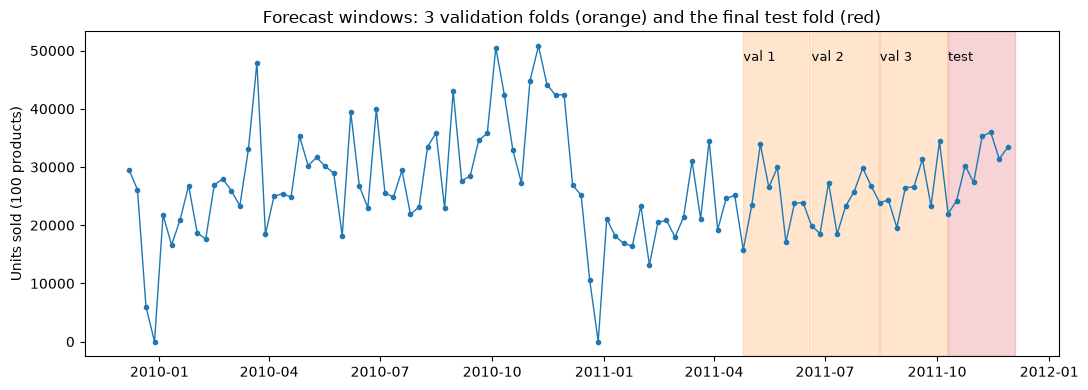

In [6]:
total = Y.sum(axis=1)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weeks, total, color="tab:blue", marker=".", linewidth=1)
for _, f in folds.iterrows():
    color = "tab:red" if f["fold"] == "test" else "tab:orange"
    ax.axvspan(f["forecast_from"], f["forecast_to"] + pd.Timedelta(days=6), color=color, alpha=0.2)
    ax.text(f["forecast_from"], total.max() * 0.95, f["fold"], fontsize=9)
ax.set_ylabel("Units sold (100 products)")
ax.set_title("Forecast windows: 3 validation folds (orange) and the final test fold (red)")
plt.tight_layout()
plt.show()

📌 **Reading this:** The three validation windows cover late April to early October 2011, where weekly demand is fairly flat (about 15,000–35,000 units). The test window covers **10 October – 28 November 2011**, the start of the gift-season rise. It is the hardest and most business-critical period, and its 8 weeks are never used for training or tuning.

## 3. Evaluation Metrics

For each fold we compare the forecast **F** with the actual units **A** over all products and all 8 forecast weeks.

| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | mean(\|F − A\|) | average error in units per product-week |
| **WAPE** | Σ\|F − A\| ÷ ΣA | error as a share of total demand (**main metric**, easy to explain: "we're off by X% of demand") |
| **Bias** | Σ(F − A) ÷ ΣA | positive = over-forecasting, negative = under-forecasting |
| **MASE** | MAE ÷ (in-sample MAE of a "same as last week" forecast), averaged over products | below 1 = better than the naive one-step forecast on that product's own history |
| **WAPE (no bulk weeks)** | WAPE, excluding product-weeks above the training-data outlier fence (Q3 + 3 × IQR) | accuracy on regular demand, without one-off bulk orders |

WAPE is preferred over MAPE because MAPE breaks when actual sales are 0 (division by zero), and weekly product sales do hit 0.

The outlier fence for "bulk weeks" is computed **only from the training weeks** of each fold, so no test information leaks into the definition.

In [7]:
def evaluate(actual, forecast, train):
    """actual, forecast: arrays (weeks x products); train: DataFrame of training weeks."""
    err = forecast - actual
    abs_err = np.abs(err)

    # MASE scale: in-sample error of "same as last week" per product
    scale = train.diff().abs().iloc[1:].mean().values

    # bulk weeks: actual above the training-data outlier fence
    q1, q3 = train.quantile(0.25).values, train.quantile(0.75).values
    normal = actual <= q3 + 3 * (q3 - q1)

    return {
        "MAE": abs_err.mean(),
        "WAPE": abs_err.sum() / actual.sum(),
        "Bias": err.sum() / actual.sum(),
        "MASE": np.nanmean(abs_err.mean(axis=0) / scale),
        "WAPE (no bulk weeks)": abs_err[normal].sum() / actual[normal].sum(),
        "bulk weeks": int((~normal).sum()),
    }

## 4. Baseline Forecasts

Each baseline uses only weeks up to the forecast origin:
- **Naive:** every future week = the last observed week.
- **Moving average (4, 8, 13 weeks):** every future week = the average of the last k weeks.
- **Seasonal naive:** each future week = the same week one year earlier (lag 52).
- **Seasonal naive, level-adjusted:** seasonal naive × (units in the last 13 weeks ÷ units in the same 13 weeks a year earlier). This keeps last year's *shape* but uses this year's *level*, which matters because our products sold less in 2011 (Part 2). The ratio is clipped to 0.5–2 so one odd week can't blow it up.

In [8]:
def baseline_forecasts(Y, e, H=HORIZON):
    """Forecasts for weeks e+1 ... e+H, using only weeks 0 ... e."""
    hist = Y.iloc[: e + 1]
    fc = {}
    fc["naive"] = np.tile(hist.iloc[-1].values, (H, 1))
    for k in [4, 8, 13]:
        fc[f"moving avg {k}"] = np.tile(hist.iloc[-k:].mean().values, (H, 1))

    seasonal = hist.iloc[e + 1 - 52 : e + 1 - 52 + H].values
    fc["seasonal naive"] = seasonal

    recent = hist.iloc[-13:].sum()
    last_year = hist.iloc[e + 1 - 52 - 13 : e + 1 - 52].sum()
    ratio = (recent / last_year.replace(0, np.nan)).fillna(1).clip(0.5, 2).values
    fc["seasonal naive (level-adj.)"] = seasonal * ratio
    return fc

### 4.1 — Score every baseline on the 3 validation folds

The test fold is **not** scored here. It stays untouched until the final comparison.

In [9]:
rows = []
for name, e in zip(folds["fold"], FOLD_ENDS):
    if name == "test":
        continue
    train = Y.iloc[: e + 1]
    actual = Y.iloc[e + 1 : e + 1 + HORIZON].values
    for method, fc in baseline_forecasts(Y, e).items():
        rows.append({"fold": name, "method": method, **evaluate(actual, fc, train)})

results = pd.DataFrame(rows)

print("WAPE per fold:")
print(results.pivot(index="method", columns="fold", values="WAPE").round(3), "\n")
print("Bulk weeks per fold:", results.groupby("fold")["bulk weeks"].first().to_dict(), "\n")

summary = (results.groupby("method")[["MAE", "WAPE", "Bias", "MASE", "WAPE (no bulk weeks)"]]
           .mean().sort_values("WAPE").round(3))
summary

WAPE per fold:
fold                         val 1  val 2  val 3
method                                          
moving avg 13                0.542  0.596  0.574
moving avg 4                 0.616  0.606  0.648
moving avg 8                 0.563  0.604  0.569
naive                        0.933  0.726  0.748
seasonal naive               0.911  0.870  0.937
seasonal naive (level-adj.)  0.852  0.825  0.949 

Bulk weeks per fold: {'val 1': 5, 'val 2': 8, 'val 3': 18} 



,MAE,WAPE,Bias,MASE,WAPE (no bulk weeks)
method,,,,,
moving avg 13,141.238,0.571,-0.046,0.775,0.552
moving avg 8,143.124,0.579,-0.023,0.786,0.560
moving avg 4,154.540,0.623,0.023,0.827,0.609
naive,198.323,0.802,0.019,1.087,0.797
seasonal naive (level-adj.),217.353,0.876,0.178,1.135,0.876
seasonal naive,224.582,0.906,0.244,1.179,0.910


📌 **Reading this:**
- **Moving average 13 is the best baseline**: WAPE **57.1%**, MASE **0.775** and almost no bias (−4.6%). The 8-week average is close behind (57.9%). Averaging over more weeks works better because it smooths out the week-to-week noise we saw in Part 2.
- **Seasonal naive is the worst** (WAPE 90.6%) and **over-forecasts by 24%**. It copies last year's numbers, but our products sell less in 2011 than in 2010. Adjusting for the level helps a little (87.6%, bias +18%), but copying a single noisy week from last year still adds a lot of error.
- A WAPE of 57% looks high, but weekly demand per product is very noisy. This is the bar to beat: **the model in Part 4 must get below 57.1% WAPE** on the same folds to be worth using.
- Bulk-order weeks are rare in the validation folds (5, 8 and 18 of 800 product-weeks), and excluding them barely changes WAPE. Most of the error comes from everyday noise, not one-off orders.

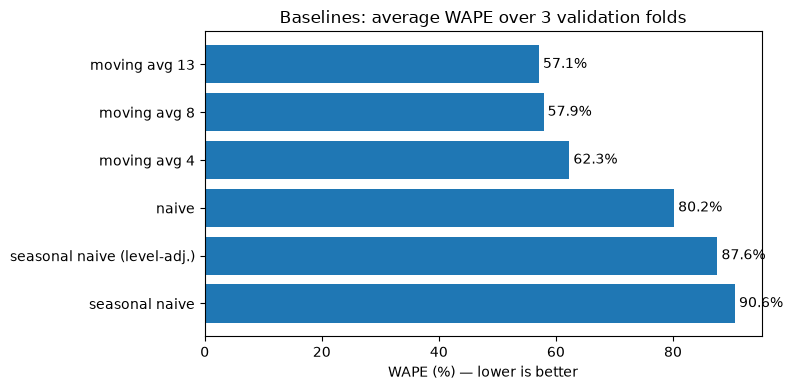

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(summary.index, summary["WAPE"] * 100, color="tab:blue")
ax.invert_yaxis()   # best on top
for i, v in enumerate(summary["WAPE"] * 100):
    ax.text(v, i, f" {v:.1f}%", va="center")
ax.set_xlabel("WAPE (%) — lower is better")
ax.set_title("Baselines: average WAPE over 3 validation folds")
plt.tight_layout()
plt.show()

📌 **Reading this:** The moving averages are clearly ahead of the naive and seasonal methods. The ranking is the same in every fold, so it is not luck.

### 4.2 — What do the forecasts look like?

The best and worst baselines for the top product in fold val 3: the moving average gives a flat line at the recent level, while seasonal naive copies last year's ups and downs.

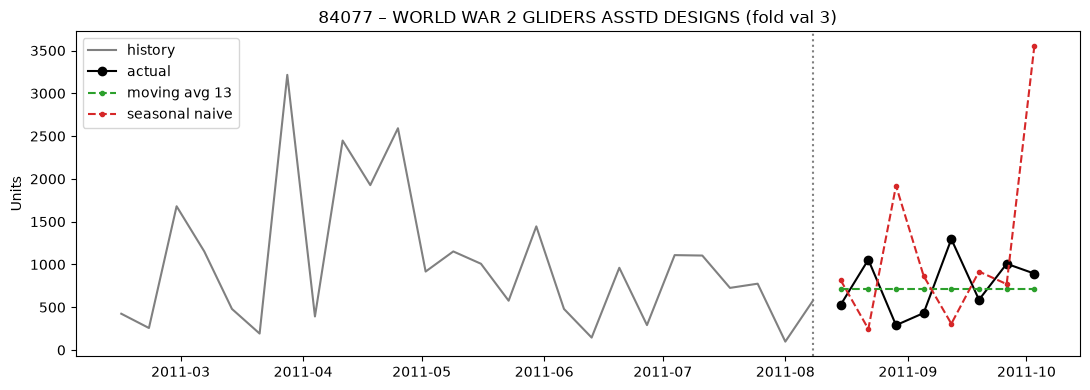

In [14]:
code = products.index[0]
e = FOLD_ENDS[2]                     # fold val 3
j = Y.columns.get_loc(code)
fc = baseline_forecasts(Y, e)
future = weeks[e + 1 : e + 1 + HORIZON]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weeks[e - 25 : e + 1], Y[code].iloc[e - 25 : e + 1], color="grey", label="history")
ax.plot(future, Y[code].iloc[e + 1 : e + 1 + HORIZON], color="black", marker="o", label="actual")
for m, c in [("moving avg 13", "tab:green"), ("seasonal naive", "tab:red")]:
    ax.plot(future, fc[m][:, j], color=c, marker=".", linestyle="--", label=m)
ax.axvline(weeks[e], color="grey", linestyle=":")
ax.set_ylabel("Units")
ax.set_title(f"{code} – {products.loc[code, 'Description'][:40]} (fold val 3)")
ax.legend()
plt.tight_layout()
plt.show()

📌 **Reading this:** The 13-week moving average forecasts a flat ~700 units, roughly through the middle of the actual sales (about 300–1,300). Seasonal naive copies last year's spikes: for the last week it forecasts about **3,550** units against an actual of about **880**, because last year that week had a one-off large sale. This is why copying a single week from last year adds so much error. In Part 4 we'll give the model a **smoothed** version of last year's demand instead.

## 5. Save the Baseline Results

We save the validation scores so Part 4 can compare the model against them on exactly the same folds.

In [15]:
results.to_csv(PROCESSED_DIR / "baseline_val_results.csv", index=False)
summary.to_csv(PROCESSED_DIR / "baseline_val_summary.csv")
print("saved baseline_val_results.csv and baseline_val_summary.csv")

saved baseline_val_results.csv and baseline_val_summary.csv


## 6. Summary

**Validation setup**
- Rolling-origin backtest with an **8-week horizon**: 3 validation folds (25 Apr – 3 Oct 2011) for comparing and tuning, and 1 test fold (10 Oct – 28 Nov 2011, gift-season peak) kept untouched for the final score.
- Metrics: **WAPE** (main), MAE, Bias, MASE, and WAPE without bulk-order weeks (fence computed from training data only).

**Baseline results (average of 3 validation folds)**

| Method | WAPE | Bias | MASE |
|---|---|---|---|
| Moving average 13 | **57.1%** | −4.6% | 0.775 |
| Moving average 8 | 57.9% | −2.3% | 0.786 |
| Moving average 4 | 62.3% | +2.3% | 0.827 |
| Naive (last week) | 80.2% | +1.9% | 1.087 |
| Seasonal naive, level-adjusted | 87.6% | +17.8% | 1.135 |
| Seasonal naive | 90.6% | +24.4% | 1.179 |

**What we learned**
- Averaging over more weeks wins, because weekly product demand is very noisy.
- Copying last year's single week is the worst method: it repeats last year's spikes and over-forecasts our slowly declining products.
- Bulk-order weeks are rare in validation, so most error is everyday noise.

**Bar to beat:** the model in Part 4 must reach a validation WAPE **below 57.1%** (moving average 13) on the same folds.

**Next (Part 4):** feature engineering in `src/features.py` (lags, rolling means, smoothed last-year demand, year-over-year ratio, calendar and UK holidays), then a global LightGBM model evaluated on the same folds.